<center>
  <h1> <strong> Análise de Otimização </strong> </h1>
  <h3> U-Net Clássica D3: grafeno </h3>
  <b>Júlia Guedes A. dos Santos & Yasmin B. Shimizu</b>
</center>
 
 
<p style="text-align: center;">
  Parte do Trabalho de Conclusão de Curso <b>Redes neurais clássicas e fuzzy para segmentação de imagens de microscopia eletrônica: desempenho e impactos socioambientais</b>, desenvolvido na Ilum Escola de Ciência do Centro Nacional de Pesquisa em Energia e Materiais (CNPEM) para obtenção do título de Bacharel em Ciência e Tecnologia.
</p>
 
<center>
  <img src="https://github.com/yasminbshimizu/FP-UNet_TEM/blob/main/imagens_README/logos_ilumcnpem.png?raw=true" width="1000"/>
</center>

### **Importação de bibliotecas**

In [2]:
import torch
import pickle
import io
import random

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import numpy as np
import seaborn as sns
from torch.utils.data import TensorDataset, DataLoader
from torchmetrics import Accuracy, Recall, Precision, Specificity, F1Score
from torchmetrics.segmentation import DiceScore
import torchmetrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc

### **Parâmetros do plot**

In [3]:
plt.rcParams.update({
    # "text.usetex": True,           
    "font.size": 12,                
    "axes.labelsize": 14,          
    "axes.titlesize": 14,
    "xtick.labelsize": 12,          
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 16,
    "figure.dpi": 300,              
    "savefig.dpi": 300              
})

### **Análise Perda**

In [4]:
df_otimizado =  pd.read_csv("perdas_otimizacao1_unetd3_grafeno.csv")

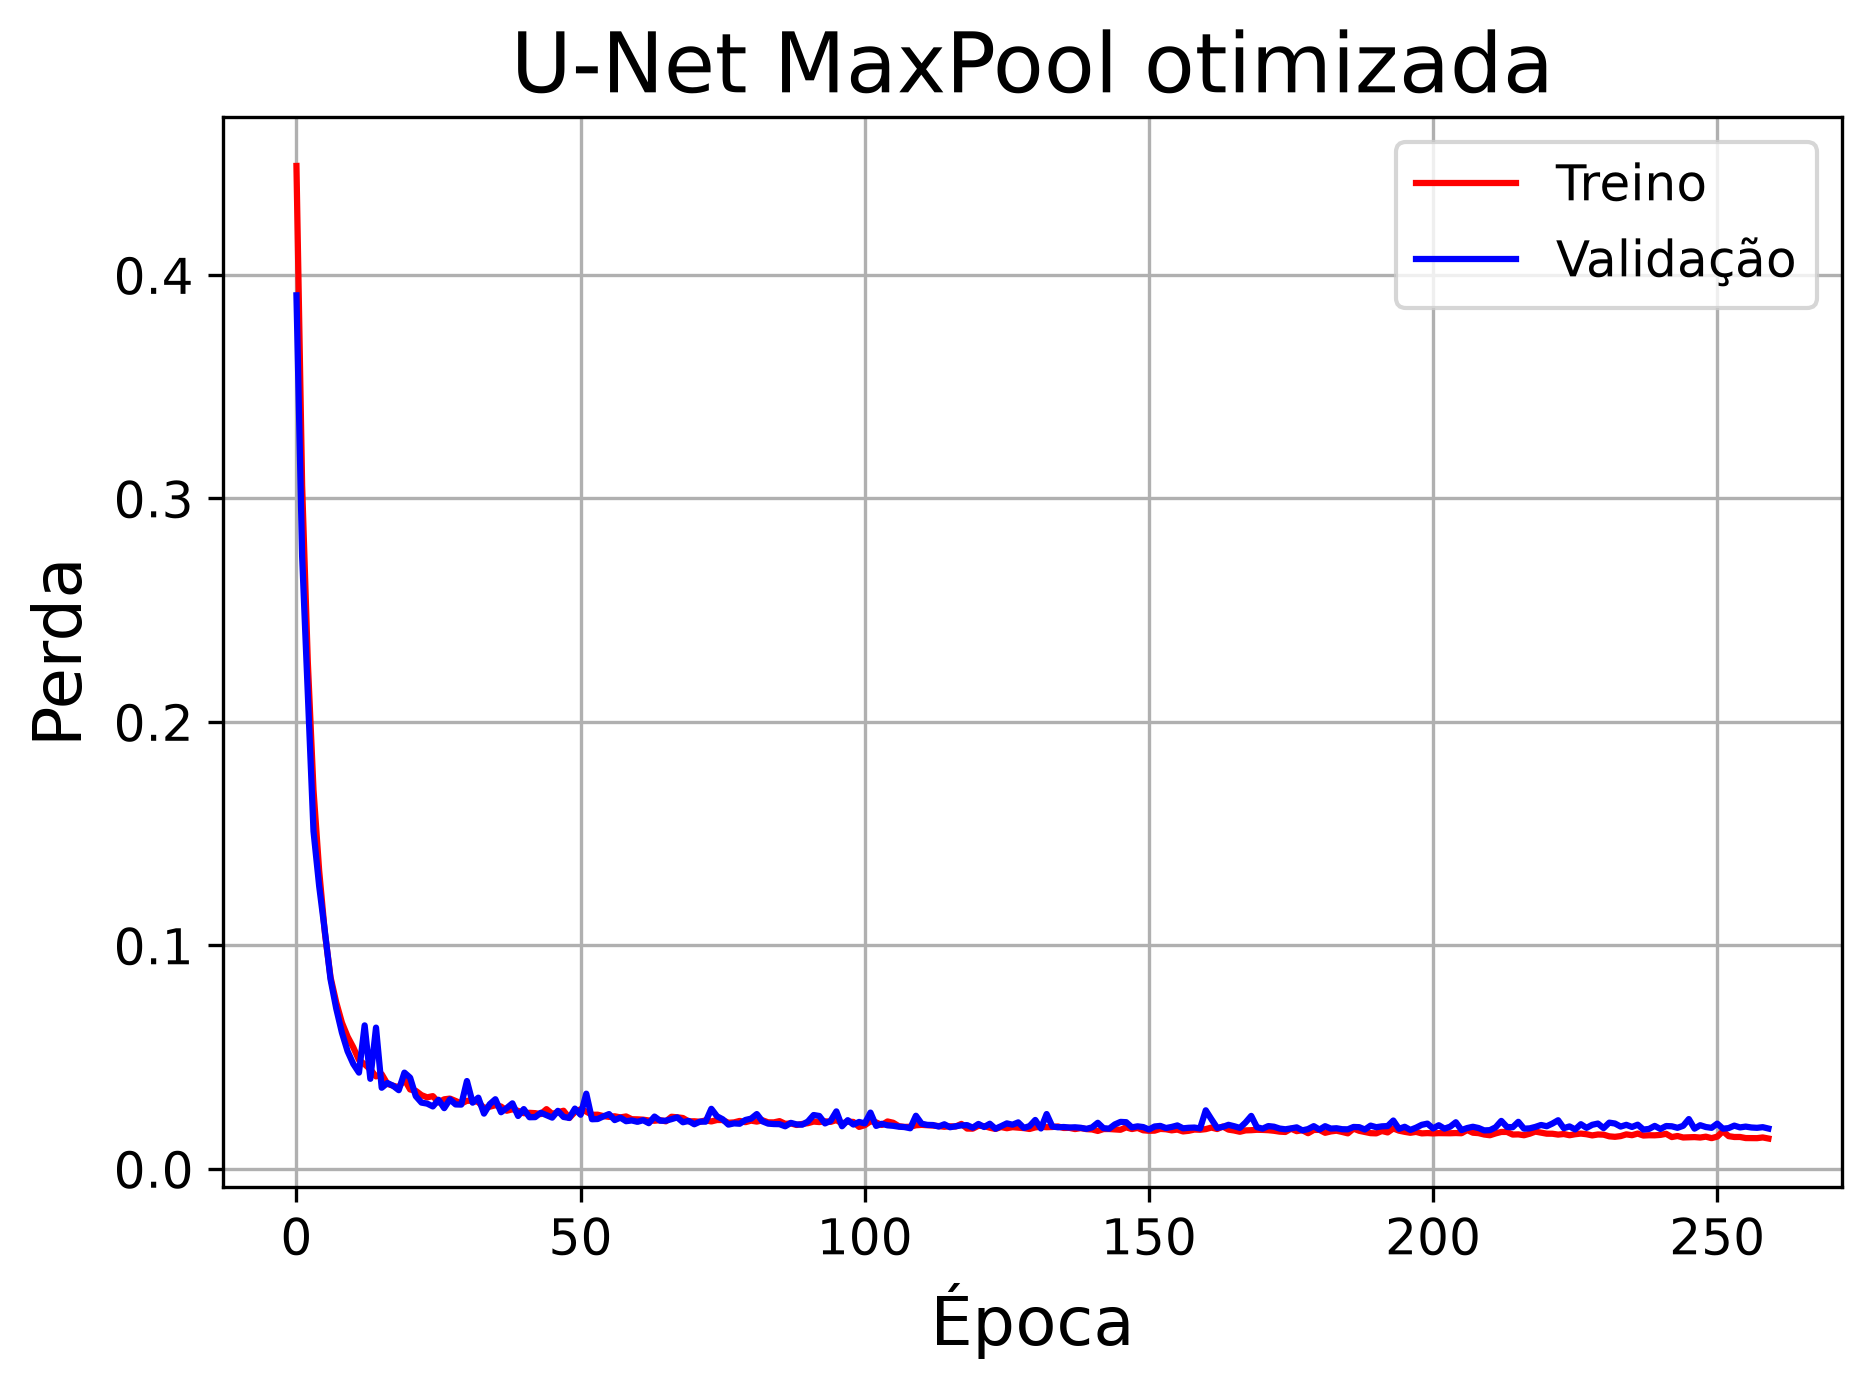

In [18]:
x0 = pontos = np.linspace(0, len(df_otimizado["Treino"]) - 1, num=len(df_otimizado["Treino"]))

x1 = pontos = np.linspace(0, len(df_otimizado["Treino"]) - 1, num=len(df_otimizado["Treino"]))
plt.plot(x1, df_otimizado["Treino"], color="Red", label="Treino")
plt.plot(x1, df_otimizado["Validação"], color="Blue", label="Validação")
plt.legend()
plt.title("U-Net MaxPool otimizada", fontsize=20)
plt.ylabel("Perda", fontsize=16)
plt.xlabel("Época", fontsize=16)
plt.grid(0.3)

plt.tight_layout()
plt.show()

### **Carregamento dos dados**

In [11]:
dados_grafeno = np.load(
        "graphene_dataset0.npz"
        )

print("Carregou os dados", flush=True)

imagens_grafeno = dados_grafeno["images"].astype(np.float32)
mascaras_grafeno = dados_grafeno["labels"].astype(np.float32)

del dados_grafeno

print("Carregou imagens e rótulos", flush=True)

print("imagens:", imagens_grafeno.shape, imagens_grafeno.dtype, imagens_grafeno.nbytes / 1024**3, "GB")
print("mascaras:", mascaras_grafeno.shape, mascaras_grafeno.dtype, mascaras_grafeno.nbytes / 1024**3, "GB")

imagens_treino_grafeno, imagens_val_grafeno, mascaras_treino_grafeno, mascaras_val_grafeno = train_test_split(
            imagens_grafeno,
            mascaras_grafeno,
            test_size=0.1,
            random_state=42
        )

print("treino:", imagens_treino_grafeno.nbytes / 1024**3, "GB")
print("val:", imagens_val_grafeno.nbytes / 1024**3, "GB")

del imagens_grafeno
del mascaras_grafeno

imagens_val_grafeno = torch.from_numpy(imagens_val_grafeno)

mascaras_val_grafeno = torch.from_numpy(mascaras_val_grafeno)

if imagens_val_grafeno.ndim == 3:

    imagens_val_grafeno = imagens_val_grafeno.unsqueeze(1)

if mascaras_val_grafeno.ndim == 3:

    mascaras_val_grafeno = mascaras_val_grafeno.unsqueeze(1)

dataset_val_grafeno = TensorDataset(imagens_val_grafeno, mascaras_val_grafeno)

loader_val_grafeno = DataLoader(
    dataset_val_grafeno,
    batch_size=8,
    shuffle=False
)

Carregou os dados
Carregou imagens e rótulos
imagens: (400, 1, 512, 512) float32 0.390625 GB
mascaras: (400, 1, 512, 512) float32 0.390625 GB
treino: 0.3515625 GB
val: 0.0390625 GB


### **U-Net MaxPool Grafeno (D3)**

In [8]:
# Salva a função original
_load_from_bytes_original_ = torch.storage._load_from_bytes

# Substitui temporariamente por uma versão que força CPU
torch.storage._load_from_bytes = lambda b: torch.load(
    io.BytesIO(b),
    map_location=torch.device("cpu"),
    weights_only=False
)

try:
    with open("U_NetD3_MaxPool_grafeno.pkl", "rb") as modelo:
        UNet_grafeno_otimizada  = pickle.load(modelo)
finally:
    # Restaura a função original
    torch.storage._load_from_bytes = _load_from_bytes_original_

UNet_grafeno_otimizada = UNet_grafeno_otimizada.to("cpu")
UNet_grafeno_otimizada.eval()

UNet_BinariaD3(
  (down1): TripleConv(
    (conv): Sequential(
      (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU6(inplace=True)
      (6): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (7): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (8): ReLU6(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): TripleConv(
    (conv): Sequential(
      (0): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_runnin

### **Previsões**

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

acuracia_binaria = Accuracy(task="binary", num_classes=2).to(device)
sensibilidade_binaria = Recall(task="binary", num_classes=2).to(device)
especificidade_binaria = Specificity(task="binary", num_classes=2).to(device)
precisao_binaria = Precision(task="binary", num_classes=2).to(device)
f1_binario = F1Score(task="binary", num_classes=2).to(device)
dice_binario = DiceScore(num_classes=2, include_background=True, average="macro", input_format="index").to(device)

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

previsoes_grafeno_otimizada = []
rotulos_reais_grafeno_otimizada = []

acuracia_binaria.reset()
sensibilidade_binaria.reset()
especificidade_binaria.reset()
precisao_binaria.reset()
f1_binario.reset()
dice_binario.reset()

with torch.no_grad():

    for imgs, mascaras in loader_val_grafeno:

        imgs = imgs.to(device)
        mascaras = mascaras.to(device).long()

        saida = UNet_grafeno_otimizada(imgs)

        preds_binarios = (saida >= 0.5).float().long()

        print(
            f"preds_binarios: "
            f"{torch.unique(preds_binarios, return_counts=True)}"
        )

        previsoes_grafeno_otimizada.extend(
            preds_binarios.cpu().numpy()
        )

        rotulos_reais_grafeno_otimizada.extend(
            mascaras.cpu().numpy()
        )

        acuracia_binaria.update(preds_binarios, mascaras)
        sensibilidade_binaria.update(preds_binarios, mascaras)
        especificidade_binaria.update(preds_binarios, mascaras)
        precisao_binaria.update(preds_binarios, mascaras)
        f1_binario.update(preds_binarios, mascaras)
        dice_binario.update(preds_binarios, mascaras)

acuracia_grafeno_otimizada = acuracia_binaria.compute().cpu().item()
sensibilidade_grafeno_otimizada = sensibilidade_binaria.compute().cpu().item()
especificidade_grafeno_otimizada = especificidade_binaria.compute().cpu().item()
precisao_grafeno_otimizada = precisao_binaria.compute().cpu().item()
f1_grafeno_otimizada = f1_binario.compute().cpu().item()
dice_grafeno_otimizada = dice_binario.compute().cpu().item()

preds_binarios: (tensor([0, 1]), tensor([1708790,  388362]))
preds_binarios: (tensor([0, 1]), tensor([1708660,  388492]))
preds_binarios: (tensor([0, 1]), tensor([1727807,  369345]))
preds_binarios: (tensor([0, 1]), tensor([1716378,  380774]))
preds_binarios: (tensor([0, 1]), tensor([1707810,  389342]))


### **Análise de resultados**

##### **Métricas**

In [13]:
print(f"Acurácia={acuracia_grafeno_otimizada*100:.2f}%")
print(f"Sensibilidade={sensibilidade_grafeno_otimizada*100:.2f}%")
print(f"Especificidade={especificidade_grafeno_otimizada*100:.2f}%")
print(f"Precisão={precisao_grafeno_otimizada*100:.2f}%")
print(f"F1={f1_grafeno_otimizada*100:.2f}%")
print(f"Dice={dice_grafeno_otimizada*100:.2f}%")

Acurácia=99.27%
Sensibilidade=97.84%
Especificidade=99.59%
Precisão=98.15%
F1=97.99%
Dice=98.77%


##### **Matriz de confusão**

In [14]:
confmat_binaria = torchmetrics.ConfusionMatrix(
    task="binary",
    num_classes=2,
    normalize="all",
).to(device)

In [15]:
previsoes_array_grafeno_otimizada = np.asarray(previsoes_grafeno_otimizada)
rotulos_array_grafeno_otimizada = np.asarray(rotulos_reais_grafeno_otimizada)

previsoes_array_grafeno_otimizada = previsoes_array_grafeno_otimizada.astype(np.float64)
rotulos_array_grafeno_otimizada = rotulos_array_grafeno_otimizada.astype(np.int64)

previsoes_tensor_grafeno_otimizada = torch.tensor(
    previsoes_array_grafeno_otimizada,
    dtype=torch.long,
    device=device
)

rotulos_tensor_grafeno_otimizada = torch.tensor(
    rotulos_array_grafeno_otimizada,
    dtype=torch.long,
    device=device
)

if previsoes_tensor_grafeno_otimizada.ndim == 4 and previsoes_tensor_grafeno_otimizada.shape[1] == 1:
    previsoes_tensor_grafeno_otimizada = previsoes_tensor_grafeno_otimizada.squeeze(1)

if rotulos_tensor_grafeno_otimizada.ndim == 4 and rotulos_tensor_grafeno_otimizada.shape[1] == 1:
    rotulos_tensor_grafeno_otimizada = rotulos_tensor_grafeno_otimizada.squeeze(1)

cm_grafeno_otimizada = confmat_binaria(
    previsoes_tensor_grafeno_otimizada,
    rotulos_tensor_grafeno_otimizada
)

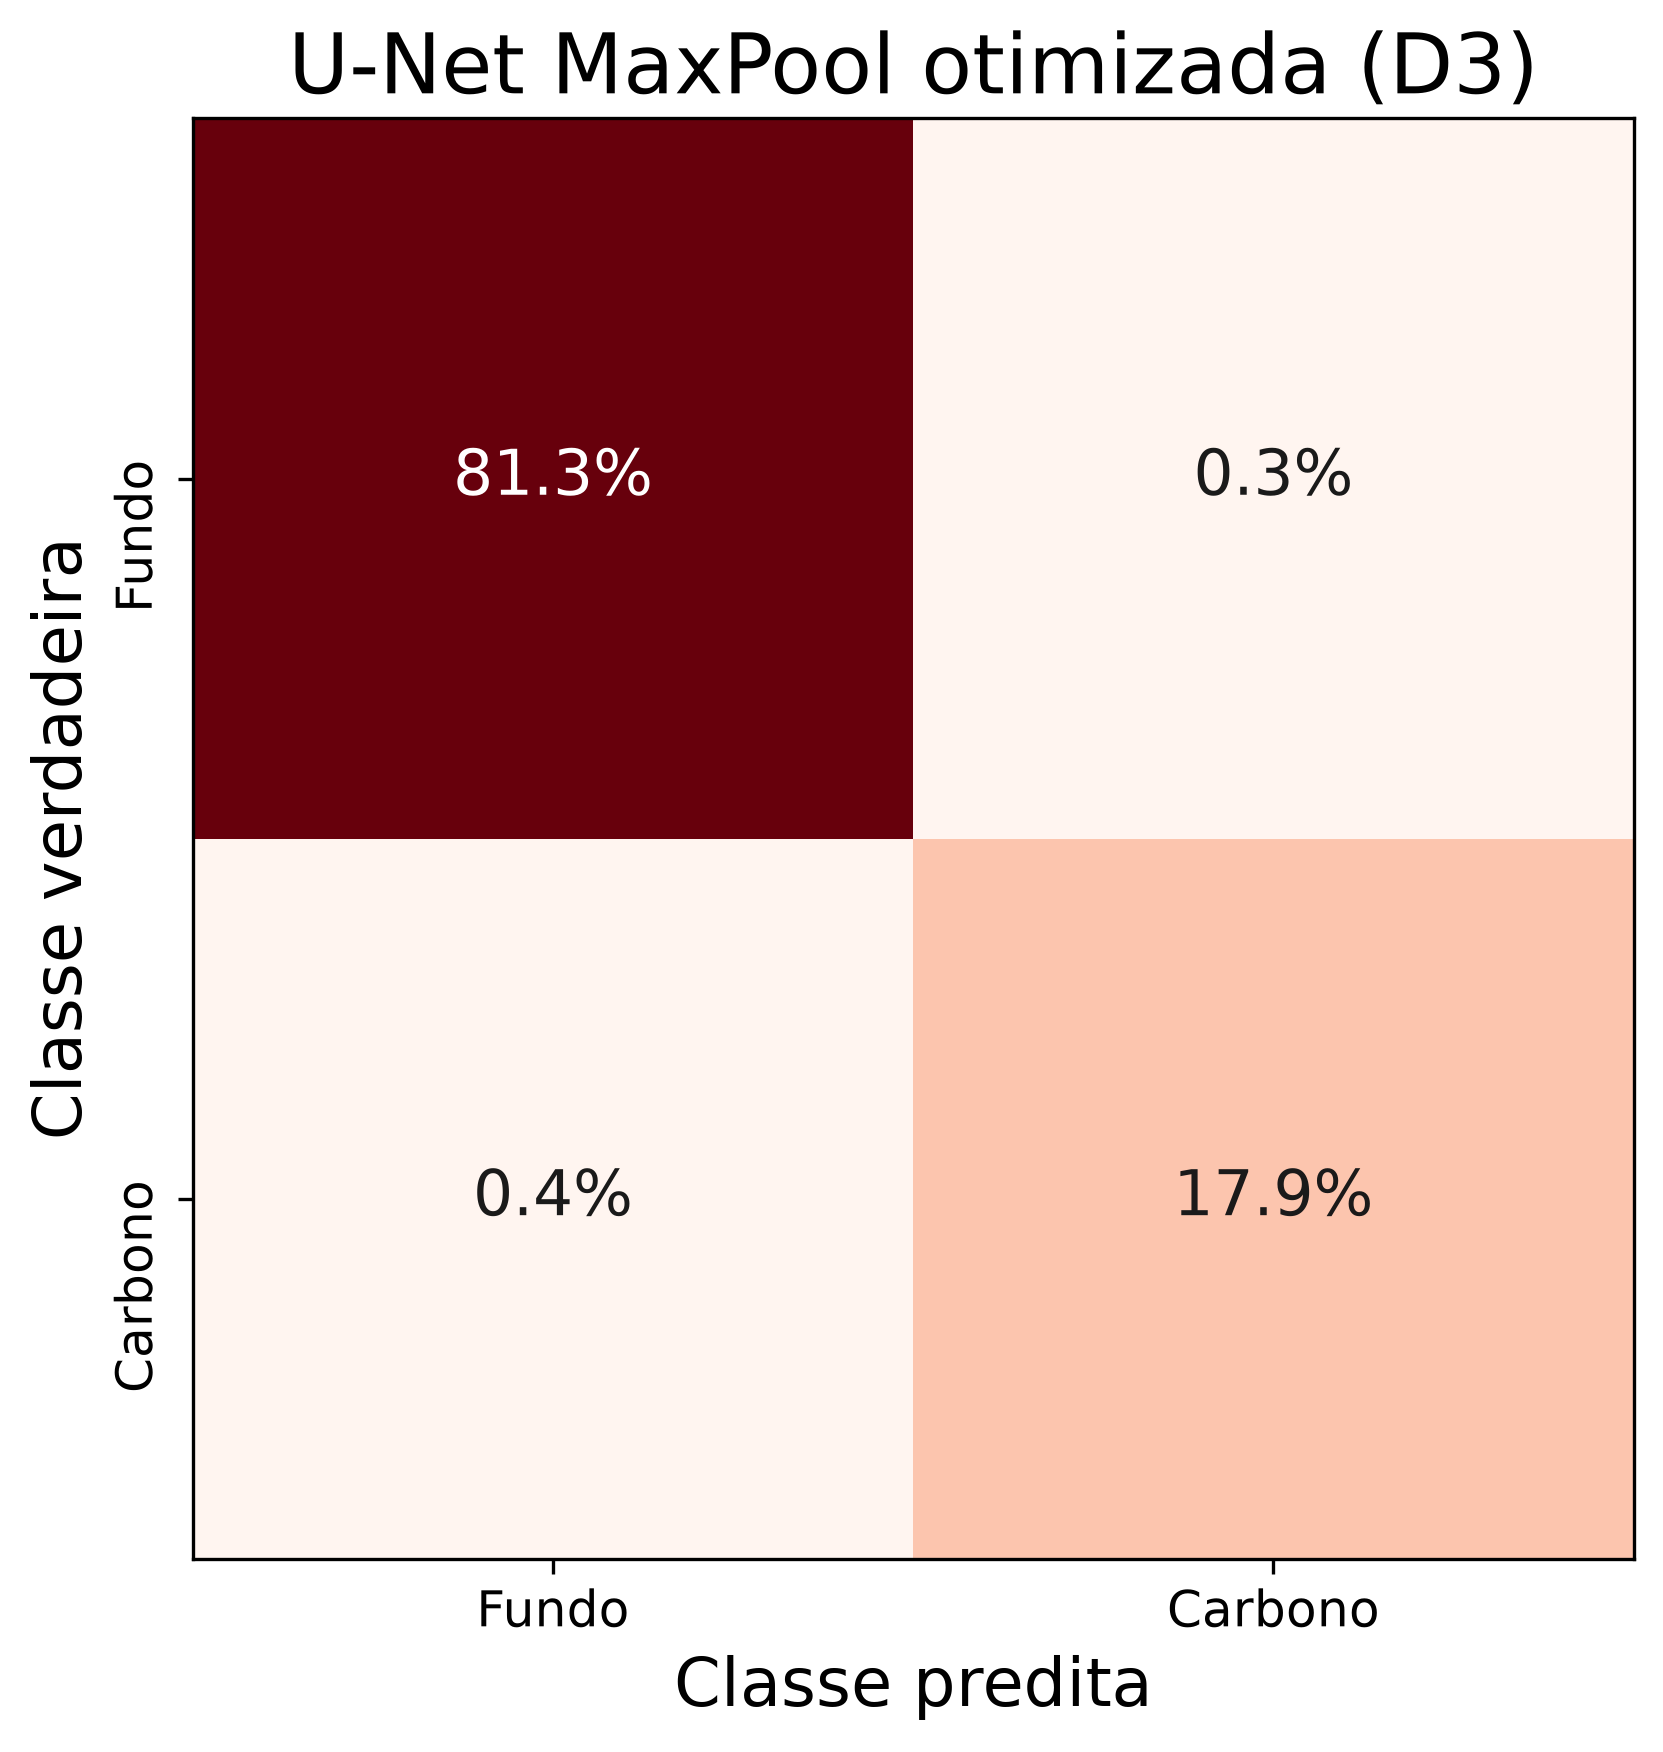

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))

confmat_binaria.plot(
    cm_grafeno_otimizada,
    ax=ax,
    cmap="Reds",
    add_text=True
)

ax.set_title("U-Net MaxPool otimizada (D3)", fontsize=20)
ax.set_ylabel("Classe verdadeira", fontsize=16)
ax.set_xlabel("Classe predita", fontsize=16)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Fundo", "Carbono"], rotation=0, fontsize=12)

ax.set_yticks([0, 1])
ax.set_yticklabels(["Fundo", "Carbono"], rotation=90, fontsize=12)

# Converte os valores da matriz de confusão em porcentagens
for texto, valor in zip(ax.texts, cm_grafeno_otimizada.flatten()):
    texto.set_text(f"{valor.item() * 100:.1f}%")

plt.tight_layout()

plt.savefig(
    "matrizes_confusao_grafeno.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##### **Curva ROC**

In [21]:
y_real_grafeno_otimizada = rotulos_tensor_grafeno_otimizada.detach().cpu().numpy().ravel()
y_score_grafeno_otimizada = previsoes_tensor_grafeno_otimizada.detach().cpu().numpy().ravel()

# Curva ROC
fpr_grafeno_otimizada, tpr_grafeno_otimizada, thresholds_grafeno_otimizada = roc_curve(y_real_grafeno_otimizada, y_score_grafeno_otimizada)

roc_auc_otimizada = auc(fpr_grafeno_otimizada, tpr_grafeno_otimizada)

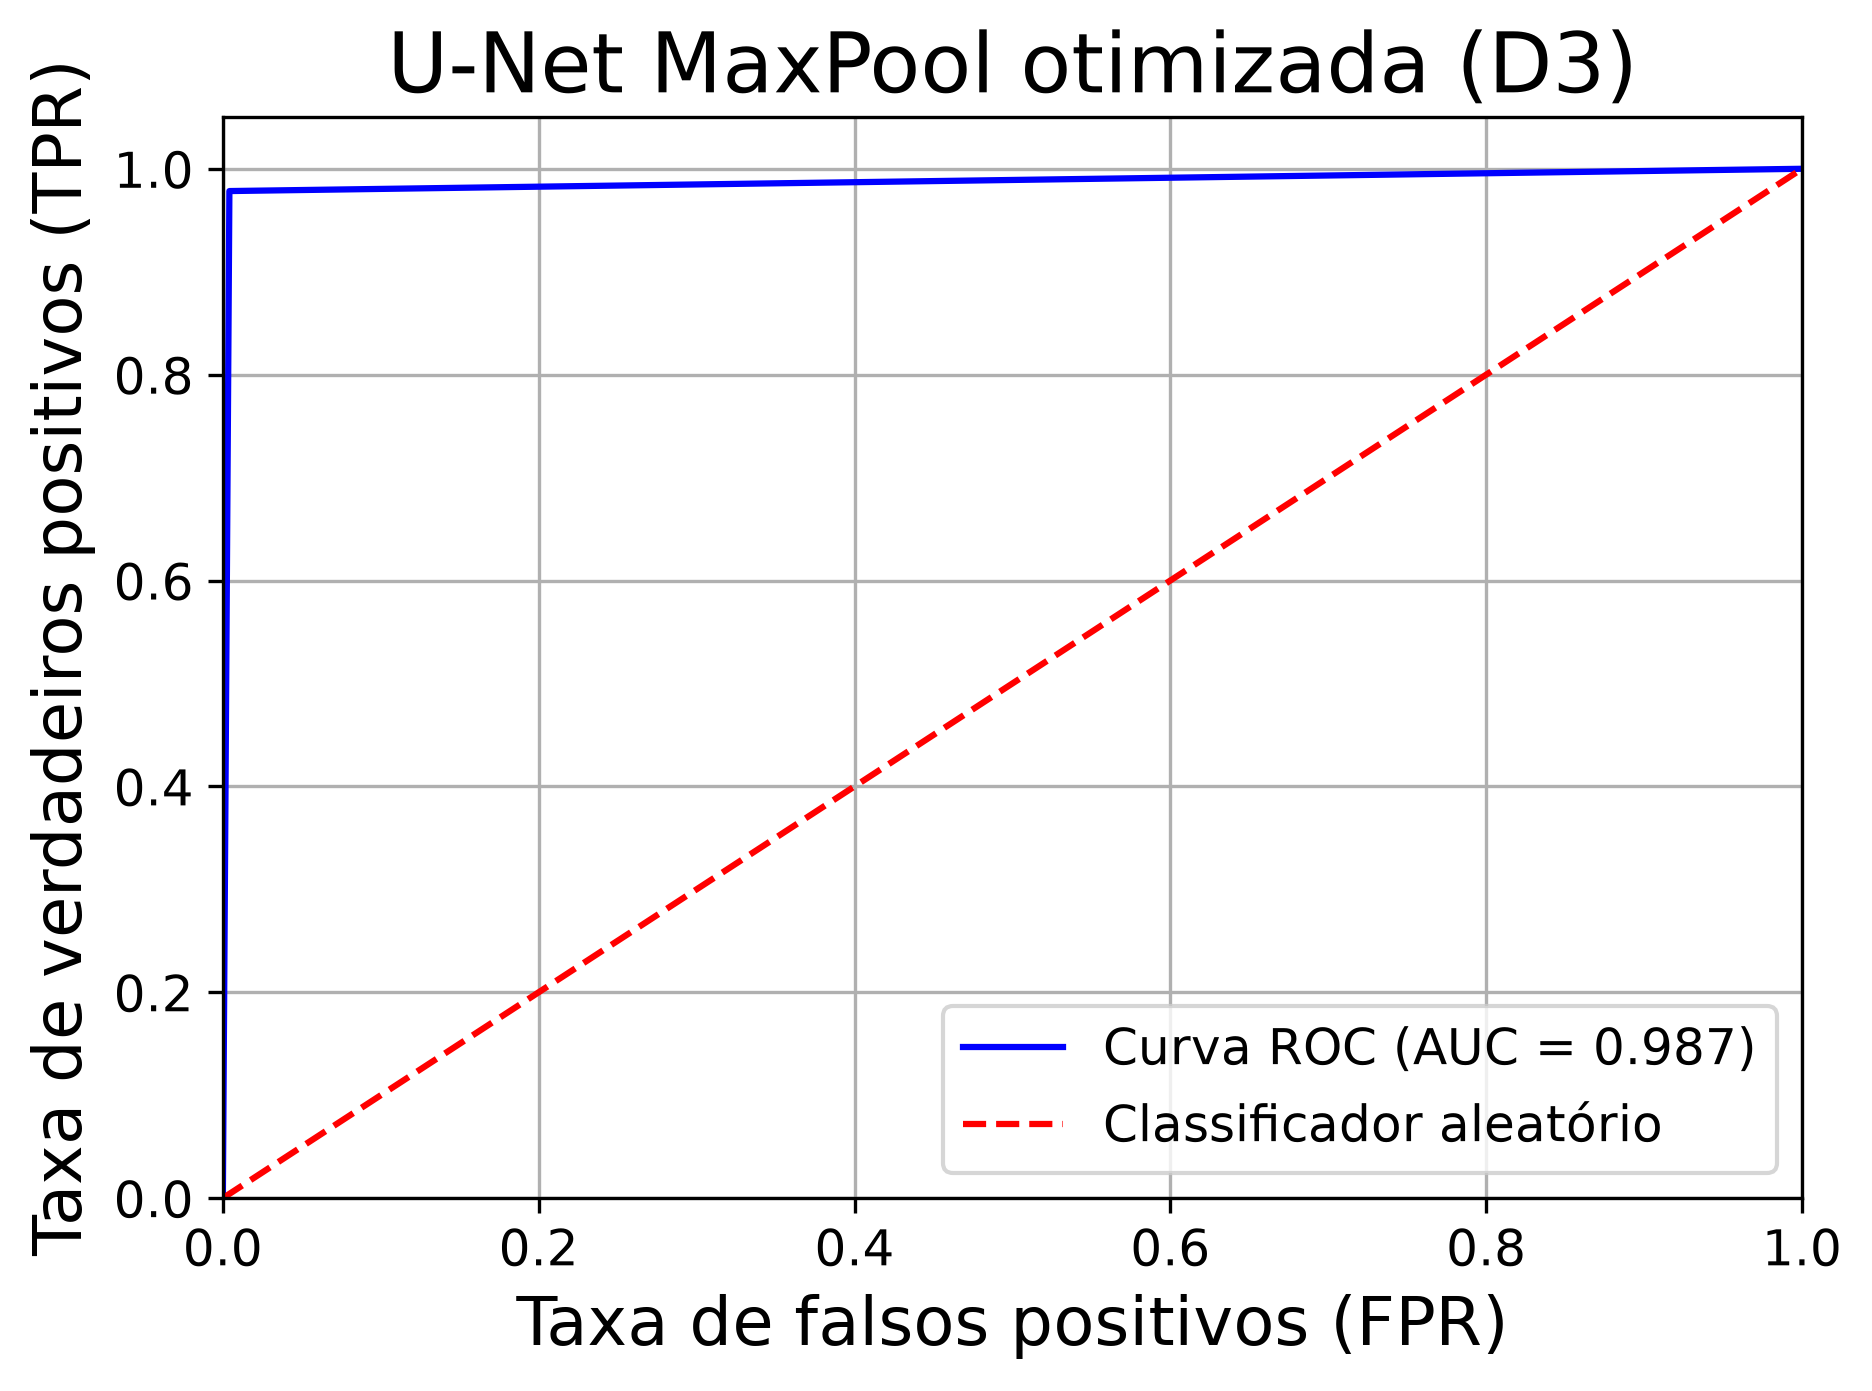

In [25]:
plt.plot(
    fpr_grafeno_otimizada,
    tpr_grafeno_otimizada,
    label=f"Curva ROC (AUC = {roc_auc_otimizada:.3f})",
    color="Blue"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Classificador aleatório", 
    color="Red"
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.xlabel("Taxa de falsos positivos (FPR)", fontsize=16)
plt.ylabel("Taxa de verdadeiros positivos (TPR)", fontsize=16)

plt.title("U-Net MaxPool otimizada (D3)", fontsize=20)

plt.legend(loc="lower right", fontsize=12)
plt.grid(0.3)

plt.tight_layout()

plt.savefig(
    "curvas_ROC_UNet_MaxPool_grafeno.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

##### **Sobreposição entre a imagem real e a máscara**

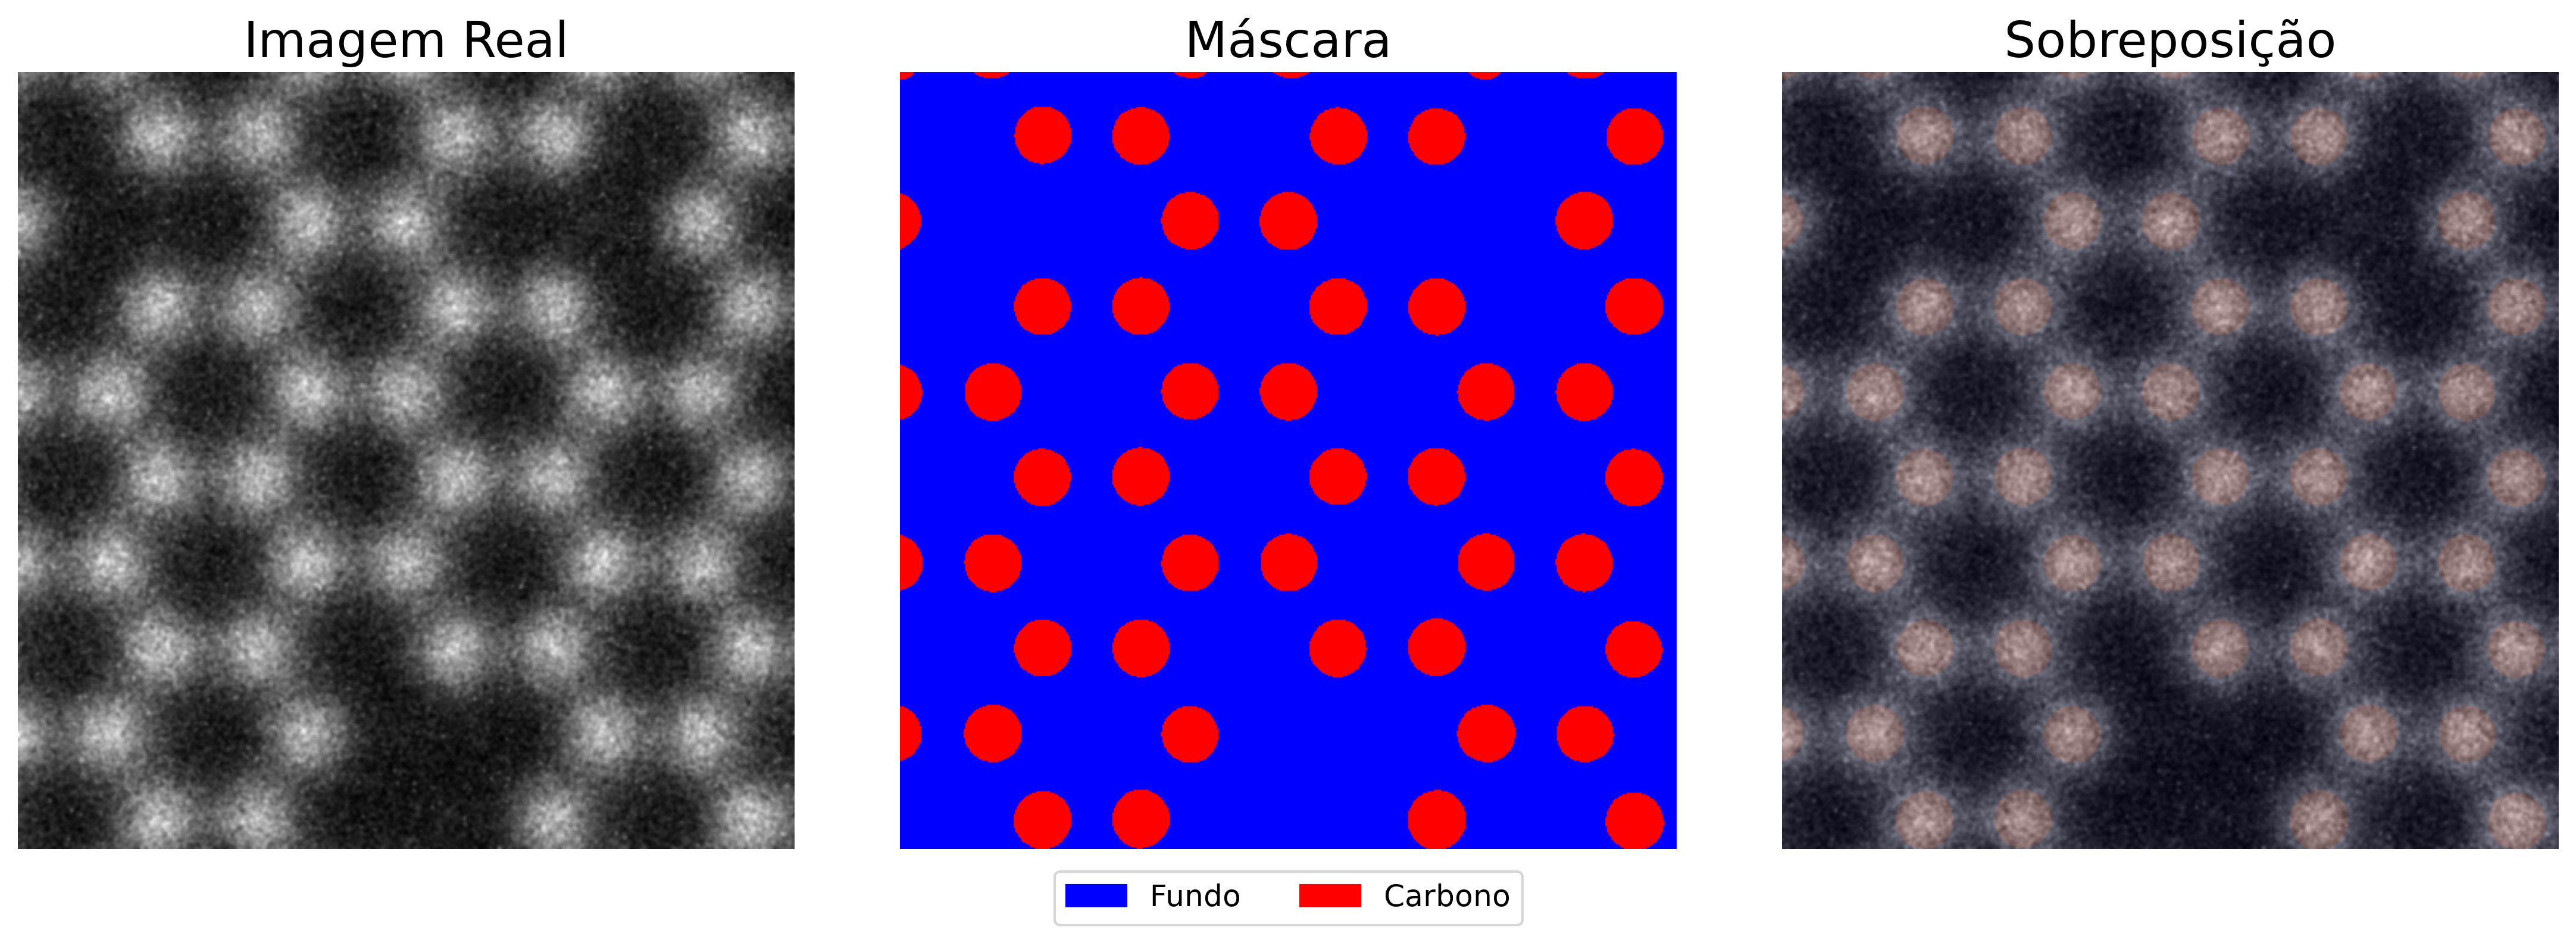

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colormap_grafeno = ListedColormap(["blue", "red"])

axes[0].imshow(imagens_val_grafeno[0][0], cmap="gray")
axes[0].set_title("Imagem Real", fontsize=20)
axes[0].axis("off")

axes[1].imshow(previsoes_grafeno_otimizada[0][0], origin='upper', cmap=colormap_grafeno)
axes[1].set_title("Máscara", fontsize=20)
axes[1].axis("off")

legenda0 = mpatches.Patch(color="blue", label="Fundo")
legenda1 = mpatches.Patch(color="red", label="Carbono")

axes[1].legend(
    handles=[legenda0, legenda1],
    loc="upper left",
    fontsize=12,
    bbox_to_anchor=(0.18, -0.01),
    ncols=2
)

axes[2].imshow(imagens_val_grafeno[0][0], cmap="gray")
axes[2].imshow(previsoes_grafeno_otimizada[0][0], origin='upper', alpha=0.2, cmap="seismic")

axes[2].set_title("Sobreposição", fontsize=20)
axes[2].axis("off")

plt.tight_layout()
plt.show()

##### **Gráfico de subtração**

C:\Users\julia24002\AppData\Local\Temp\ipykernel_25032\1255807874.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  subtracao_otimizada = mascaras_val_grafeno[0][0] - previsoes_grafeno_otimizada[0][0]
C:\Users\julia24002\AppData\Local\Temp\ipykernel_25032\1255807874.py:10: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  subtracao_otimizada = mascaras_val_grafeno[0][0] - previsoes_grafeno_otimizada[0][0]


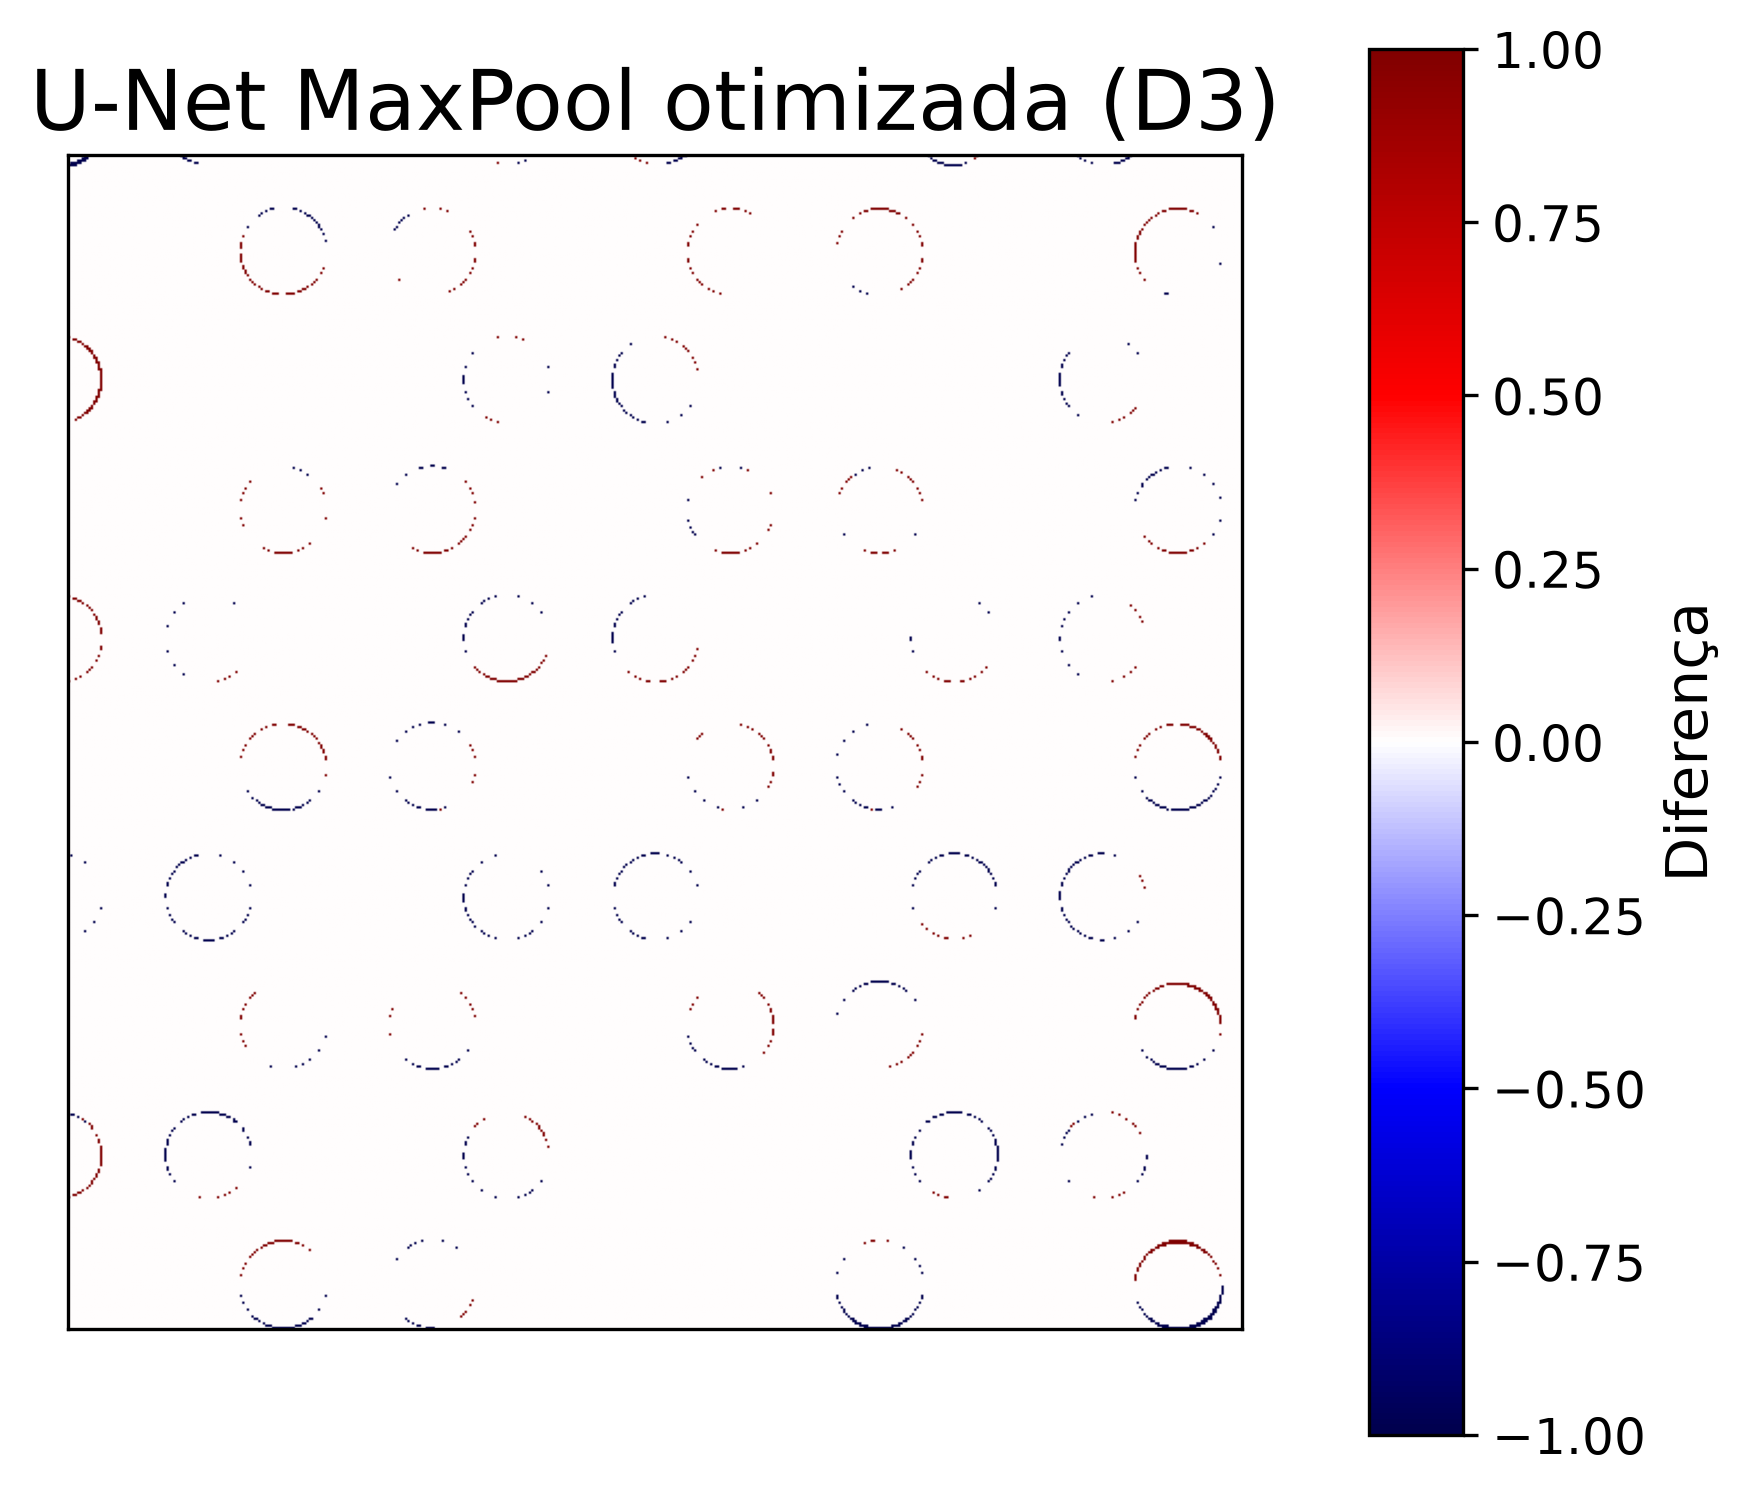

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(6,6), gridspec_kw={"width_ratios": [1, 0.08]})

subtracao_otimizada = mascaras_val_grafeno[0][0] - previsoes_grafeno_otimizada[0][0]

axes[0].set_title("U-Net MaxPool otimizada (D3)", fontsize=20)
axes[0].imshow(subtracao_otimizada, cmap="seismic")
axes[0].set_xticks([])
axes[0].set_yticks([])

subtracao_otimizada = mascaras_val_grafeno[0][0] - previsoes_grafeno_otimizada[0][0]
im = axes[0].imshow(
        subtracao_otimizada,
        cmap="seismic",
        vmin=-1,
        vmax=1
    )

cbar = fig.colorbar(im, cax=axes[1])
cbar.set_label("Diferença", fontsize=14)

plt.show()